# 02 - Modelling and evaluation

**Question:** can a screening model trained on a large exam-based dataset (A, Cardio) also rank people by their
10-year coronary heart disease outcome in an independent cohort (B, Framingham), using only 8 shared measurements?

| Step | What it does |
|---|---|
| Exp 1 | Nested 5-fold cross-validation on A (tuning inside each training fold) |
| Selection | Uses Exp 1 only: highest recall at 70% specificity; models within 0.02 are tied and ranked by ROC-AUC |
| Exp 2 | Train on all of A, test on all of B |
| Exp 2b | Same, without `smoker` |
| Exp 2c | Same as Exp 2, but B's cholesterol and glucose levels re-binned to match A's level shares |
| Exp 2d | Same as Exp 2, but only B rows with no missing shared attribute |
| Exp 3 | Reference only: train and test inside Framingham, to show what B's own label allows. Plays no part in selection |

B is never used to choose a model, tune a setting or fit an imputer. On B the headline numbers are ROC-AUC and PR-AUC,
which do not depend on a cutoff, because the two labels have different prevalence (A about 50%, B about 15%).

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedKFold

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as pp
import rules as rl

FIG = ROOT / "outputs" / "figures"
RES = ROOT / "outputs" / "results"
MODELS = ROOT / "models"
for d in (FIG, RES, MODELS):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
SPEC_TARGET = 0.70      # selection: recall at 70% specificity
RECALL_TARGET = 0.75    # app cutoff: the score cutoff giving 75% recall on A's out-of-fold predictions
TOP_SHARE = 0.30        # recall when flagging the top 30% of scores
COLORS = {"Logistic Regression": "#4E79A7", "Random Forest": "#59A14F", "Gradient Boosting": "#E15759", "Rule count": "#9AA0A6"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 200, "display.max_columns", 40)


def log(msg):
    print(msg)
    print(msg, file=sys.stderr, flush=True)

## 1. Load A and B
`dataset_A.csv` and `dataset_B.csv` are written by `src/make_dataset.py` (notebook 01 runs it).

In [2]:
a = pd.read_csv(ROOT / "data" / "processed" / "dataset_A.csv")
b = pd.read_csv(ROOT / "data" / "processed" / "dataset_B.csv")
FEATURES = pp.SHARED
FEATURES_NO_SMOKER = [c for c in pp.SHARED if c != "smoker"]
XA, yA = pp.get_X(a), a[pp.TARGET].values
XB, yB = pp.get_X(b), b[pp.TARGET].values
print(f"A: {len(a):,} rows, positive rate {yA.mean():.3f}")
print(f"B: {len(b):,} rows, positive rate {yB.mean():.3f}, rows with any missing shared attribute: {int(XB.isna().any(axis=1).sum())}")
print("features:", FEATURES)

A: 68,515 rows, positive rate 0.495
B: 4,238 rows, positive rate 0.152, rows with any missing shared attribute: 412
features: ['age', 'sex', 'sysbp', 'diabp', 'bmi', 'smoker', 'chol_level', 'gluc_level']


## 2. The three models and their (deliberately small) grids

A is large and has only 8 attributes, so a small grid is enough. Gradient Boosting is scikit-learn's histogram-based
implementation (`HistGradientBoostingClassifier`), which is much faster on 68,000 rows. Imputation and one-hot encoding of
the levels are inside the pipeline, so they are fitted on training data only. Scaling is applied for Logistic Regression only.
Inside each training fold the grid is searched with 3-fold cross-validation on ROC-AUC.

In [3]:
MODEL_SPECS = {
    "Logistic Regression": dict(
        estimator=LogisticRegression(max_iter=2000), scale=True,
        grid={"clf__C": [0.1, 1.0, 10.0]}),
    "Random Forest": dict(
        estimator=RandomForestClassifier(n_estimators=150, n_jobs=2, random_state=SEED), scale=False,
        grid={"clf__max_depth": [6, 10], "clf__min_samples_leaf": [20, 100]}),
    "Gradient Boosting": dict(
        estimator=HistGradientBoostingClassifier(random_state=SEED), scale=False,
        grid={"clf__max_leaf_nodes": [8, 31], "clf__learning_rate": [0.05, 0.1]}),
}


def make_search(name, features):
    spec = MODEL_SPECS[name]
    pipe = pp.build_pipeline(clone(spec["estimator"]), features, scale=spec["scale"])
    inner = StratifiedKFold(3, shuffle=True, random_state=SEED)
    return GridSearchCV(pipe, spec["grid"], scoring="roc_auc", cv=inner, n_jobs=1, refit=True)


for name, spec in MODEL_SPECS.items():
    print(f"{name:20s} grid: {spec['grid']}")

Logistic Regression  grid: {'clf__C': [0.1, 1.0, 10.0]}
Random Forest        grid: {'clf__max_depth': [6, 10], 'clf__min_samples_leaf': [20, 100]}
Gradient Boosting    grid: {'clf__max_leaf_nodes': [8, 31], 'clf__learning_rate': [0.05, 0.1]}


## 3. Metrics

* **recall, specificity, precision, F1** at a stated cutoff
* **ROC-AUC** and **PR-AUC** (cutoff-free). The PR-AUC baseline is the positive rate (about 15% on B)
* **recall at 70% specificity** and **recall when flagging the top 30% of scores**: both are read off the ranking, so they do not depend on how a model scales its probabilities

In [4]:
def recall_at_specificity(y, p, spec=SPEC_TARGET):
    fpr, tpr, _ = roc_curve(y, p)
    return float(tpr[fpr <= 1 - spec].max())


def recall_top_share(y, p, share=TOP_SHARE):
    k = int(round(len(p) * share))
    top = np.argsort(-p, kind="mergesort")[:k]
    return float(y[top].sum() / y.sum())


def cutoff_for_recall(y, p, target=RECALL_TARGET):
    """Highest cutoff whose recall is at least `target`."""
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr >= target)])


def youden_cutoff(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])


def metric_row(y, p, cutoff=0.5):
    y = np.asarray(y); p = np.asarray(p)
    pred = (p >= cutoff).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fp = int(((pred == 1) & (y == 0)).sum())
    tn = int(((pred == 0) & (y == 0)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    recall = tp / (tp + fn); spec = tn / (tn + fp)
    prec = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * prec * recall / (prec + recall) if tp + fp and prec + recall else np.nan
    return {"cutoff": cutoff, "recall": recall, "specificity": spec, "precision": prec, "f1": f1,
            "roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "prevalence": y.mean(),
            "recall_at_70spec": recall_at_specificity(y, p), "recall_top30": recall_top_share(y, p),
            "flagged_pct": pred.mean() * 100, "tp": tp, "fp": fp, "tn": tn, "fn": fn}


def boot_ci(y, p, fn, n=500, seed=SEED):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        vals.append(fn(y[i], p[i]))
    return tuple(np.percentile(vals, [2.5, 97.5]))


print("metric functions ready")

metric functions ready


## 4. Experiment 1 - nested 5-fold cross-validation on A

Outer loop: 5 stratified folds. In each outer training part the grid is tuned by an inner 3-fold search, then the tuned
model is scored on the untouched outer fold. The out-of-fold predictions of all five folds are kept: they are used for
the ROC curves, the score cutoffs and the permutation importance. Fold-level metrics use a 0.5 cutoff (the "recall at 0.5" column is a secondary measure).

In [5]:
t0 = time.time()
outer = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof = {name: np.zeros(len(a)) for name in MODEL_SPECS}
fold_rows, fold_models = [], {name: [] for name in MODEL_SPECS}
for f, (tr, te) in enumerate(outer.split(XA, yA), 1):
    for name in MODEL_SPECS:
        s = make_search(name, FEATURES)
        s.fit(XA.iloc[tr], yA[tr])
        p = s.predict_proba(XA.iloc[te])[:, 1]
        oof[name][te] = p
        row = metric_row(yA[te], p, 0.5)
        row.update(model=name, fold=f, best_params=json.dumps(s.best_params_))
        fold_rows.append(row)
        fold_models[name].append((s.best_estimator_, te))
        log(f"fold {f} {name:20s} AUC {row['roc_auc']:.4f}  recall@70spec {row['recall_at_70spec']:.4f}  ({time.time()-t0:.0f}s)")
    pd.DataFrame(fold_rows).to_csv(RES / "exp1_cv_fold_metrics.csv", index=False)

folds = pd.DataFrame(fold_rows)
cols = ["model", "fold", "roc_auc", "pr_auc", "recall_at_70spec", "recall_top30", "recall", "specificity", "precision", "f1", "best_params"]
folds[cols].to_csv(RES / "exp1_cv_fold_metrics.csv", index=False)
exp1_summary = folds.groupby("model")[["roc_auc", "pr_auc", "recall_at_70spec", "recall_top30", "recall", "specificity", "precision", "f1"]].agg(["mean", "std"])
print(f"Exp 1 finished in {time.time()-t0:.0f}s")
exp1_summary.round(4)

fold 1 Logistic Regression  AUC 0.7868  recall@70spec 0.7403  (1s)


fold 1 Logistic Regression  AUC 0.7868  recall@70spec 0.7403  (1s)


fold 1 Random Forest        AUC 0.7951  recall@70spec 0.7501  (14s)


fold 1 Random Forest        AUC 0.7951  recall@70spec 0.7501  (14s)


fold 1 Gradient Boosting    AUC 0.7965  recall@70spec 0.7499  (18s)


fold 1 Gradient Boosting    AUC 0.7965  recall@70spec 0.7499  (18s)


... (21 outputs left out)

fold 5 Random Forest        AUC 0.8018  recall@70spec 0.7626  (81s)


fold 5 Gradient Boosting    AUC 0.8021  recall@70spec 0.7602  (85s)


fold 5 Gradient Boosting    AUC 0.8021  recall@70spec 0.7602  (85s)
Exp 1 finished in 85s


roc_auc          pr_auc         recall_at_70spec         recall_top30          recall         specificity         precision              f1        
                       mean     std    mean     std             mean     std         mean     std    mean     std        mean     std      mean     std    mean     std
model                                                                                                                                                                  
Gradient Boosting    0.8001  0.0034  0.7820  0.0035           0.7555  0.0049       0.5058  0.0031  0.6959  0.0097      0.7714  0.0063    0.7489  0.0028  0.7214  0.0042
Logistic Regression  0.7906  0.0037  0.7705  0.0067           0.7473  0.0050       0.4973  0.0021  0.6612  0.0045      0.7902  0.0050    0.7553  0.0044  0.7051  0.0034
Random Forest        0.7996  0.0037  0.7812  0.0039           0.7573  0.0049       0.5060  0.0031  0.6737  0.0077      0.7918  0.0063    0.7601  0.0043  0.7143  0.0041

## 5. Model selection (Exp 1 only)

The score is the mean recall at 70% specificity across the five outer folds. Any model within 0.02 of the best is
treated as tied, and the tie is broken by mean ROC-AUC. B plays no part here.

In [6]:
sel = folds.groupby("model").agg(recall70_mean=("recall_at_70spec", "mean"), recall70_sd=("recall_at_70spec", "std"),
                                 auc_mean=("roc_auc", "mean"), auc_sd=("roc_auc", "std"))
best_recall = sel["recall70_mean"].max()
sel["tied_with_best"] = sel["recall70_mean"] >= best_recall - 0.02
tied = sel[sel["tied_with_best"]]
BEST = tied["auc_mean"].idxmax()
sel["selected"] = sel.index == BEST
print(f"Best mean recall at 70% specificity: {best_recall:.4f}")
print(f"Models within 0.02: {', '.join(tied.index)}")
print(f"Selected model (highest ROC-AUC among the tied): {BEST}")
sel.round(4)

Best mean recall at 70% specificity: 0.7573
Models within 0.02: Gradient Boosting, Logistic Regression, Random Forest
Selected model (highest ROC-AUC among the tied): Gradient Boosting


,recall70_mean,recall70_sd,auc_mean,auc_sd,tied_with_best,selected
model,,,,,,
Gradient Boosting,0.7555,0.0049,0.8001,0.0034,True,True
Logistic Regression,0.7473,0.0050,0.7906,0.0037,True,False
Random Forest,0.7573,0.0049,0.7996,0.0037,True,False


## 6. Final models, trained on all of A

The grid is searched once more on all of A (3-fold), and the winning setting is refitted on all 68,515 rows.
The score cutoffs are computed from A's pooled out-of-fold predictions only:

* **recall-75 cutoff:** the highest cutoff that still catches 75% of the positives. This is the cutoff the app uses.
* **Youden cutoff:** the cutoff maximising recall + specificity - 1, stored for reference only.

In [7]:
final, best_params, cutoffs = {}, {}, {}
for name in MODEL_SPECS:
    s = make_search(name, FEATURES).fit(XA, yA)
    final[name] = s.best_estimator_
    best_params[name] = {k: (v.item() if hasattr(v, "item") else v) for k, v in s.best_params_.items()}
    cutoffs[name] = {"recall75": cutoff_for_recall(yA, oof[name]), "youden": youden_cutoff(yA, oof[name])}
    log(f"{name:20s} best params {best_params[name]}  cutoffs {cutoffs[name]}")
pd.DataFrame({n: {**best_params[n], **cutoffs[n]} for n in MODEL_SPECS}).T

Logistic Regression  best params {'clf__C': 10.0}  cutoffs {'recall75': 0.43314597443669073, 'youden': 0.481450241293738}


Logistic Regression  best params {'clf__C': 10.0}  cutoffs {'recall75': 0.43314597443669073, 'youden': 0.481450241293738}


Random Forest        best params {'clf__max_depth': 10, 'clf__min_samples_leaf': 20}  cutoffs {'recall75': 0.42117461170729426, 'youden': 0.4877995669994461}


Random Forest        best params {'clf__max_depth': 10, 'clf__min_samples_leaf': 20}  cutoffs {'recall75': 0.42117461170729426, 'youden': 0.4877995669994461}


Gradient Boosting    best params {'clf__learning_rate': 0.1, 'clf__max_leaf_nodes': 8}  cutoffs {'recall75': 0.42589127811735783, 'youden': 0.4987774829660293}


Gradient Boosting    best params {'clf__learning_rate': 0.1, 'clf__max_leaf_nodes': 8}  cutoffs {'recall75': 0.42589127811735783, 'youden': 0.4987774829660293}


,clf__C,recall75,youden,clf__max_depth,clf__min_samples_leaf,clf__learning_rate,clf__max_leaf_nodes
Logistic Regression,10.0,0.433146,0.481450,NaN,NaN,NaN,NaN
Random Forest,NaN,0.421175,0.487800,10.0,20.0,NaN,NaN
Gradient Boosting,NaN,0.425891,0.498777,NaN,NaN,0.1,8.0


## 7. Experiments 2, 2b, 2c, 2d - train on A, test on B

* **Exp 2:** final models (all 8 attributes), all 4,238 rows of B. Missing values in B are filled with A's median (BMI) or A's most common level (cholesterol, glucose).
* **Exp 2b:** the same without `smoker`; models are re-tuned and refitted on A without that column.
* **Exp 2c:** the Exp 2 models, but B's cholesterol and glucose (mg/dl) are cut into levels so that the share of each level matches A's. This uses B's feature values and A's level shares, never B's labels.
* **Exp 2d:** the Exp 2 models, scored only on B rows with no missing shared attribute.

Cutoff-based columns (recall, specificity, precision, F1) use each model's recall-75 cutoff from A and are shown for Exp 2, 2c and 2d.
They are not comparable to A's numbers because B's prevalence is different. Exp 2b has no A-derived cutoff, so only cutoff-free metrics are given.

In [8]:
def evaluate(experiment, name, y, p, cutoff=None):
    row = metric_row(y, p, cutoff if cutoff is not None else 0.5)
    if cutoff is None:
        for k in ("cutoff", "recall", "specificity", "precision", "f1", "flagged_pct", "tp", "fp", "tn", "fn"):
            row[k] = np.nan
    lo, hi = boot_ci(y, p, roc_auc_score)
    plo, phi = boot_ci(y, p, average_precision_score)
    row.update(experiment=experiment, model=name, n=len(y), positives=int(y.sum()),
               roc_auc_ci_low=lo, roc_auc_ci_high=hi, pr_auc_ci_low=plo, pr_auc_ci_high=phi)
    return row


cross, pred_B = [], {}
t0 = time.time()

# Exp 2
for name in MODEL_SPECS:
    p = final[name].predict_proba(XB)[:, 1]
    pred_B[name] = p
    cross.append(evaluate("Exp 2: train A, test B", name, yB, p, cutoffs[name]["recall75"]))
log(f"Exp 2 done ({time.time()-t0:.0f}s)")

# Exp 2b: no smoker (re-tuned on A)
final_ns = {}
for name in MODEL_SPECS:
    s = make_search(name, FEATURES_NO_SMOKER).fit(pp.get_X(a, FEATURES_NO_SMOKER), yA)
    final_ns[name] = s.best_estimator_
    p = s.predict_proba(pp.get_X(b, FEATURES_NO_SMOKER))[:, 1]
    cross.append(evaluate("Exp 2b: without smoker", name, yB, p))
    log(f"Exp 2b {name} done ({time.time()-t0:.0f}s)")

# Exp 2c: B's levels re-binned to match A's level shares
raw_b = pd.read_csv(ROOT / "data" / "raw" / "framingham.csv", na_values=["NA"])
assert len(raw_b) == len(b) and (raw_b["TenYearCHD"].values == yB).all(), "raw and processed Framingham rows do not line up"
shares_a = {c: [pp.level_shares(a[c])[k] for k in (1, 2, 3)] for c in pp.LEVELS}
chol_cuts = pp.quantile_cutoffs(raw_b["totChol"], shares_a["chol_level"])
gluc_cuts = pp.quantile_cutoffs(raw_b["glucose"], shares_a["gluc_level"])
b_rebin = b.copy()
b_rebin["chol_level"] = pp.bin_by_cutoffs(raw_b["totChol"], chol_cuts)
b_rebin["gluc_level"] = pp.bin_by_cutoffs(raw_b["glucose"], gluc_cuts)
XB_rebin = pp.get_X(b_rebin)
for name in MODEL_SPECS:
    p = final[name].predict_proba(XB_rebin)[:, 1]
    cross.append(evaluate("Exp 2c: B levels re-binned to A's shares", name, yB, p, cutoffs[name]["recall75"]))
log(f"Exp 2c done ({time.time()-t0:.0f}s)")

# Exp 2d: complete cases only
complete = ~XB.isna().any(axis=1).values
for name in MODEL_SPECS:
    p = pred_B[name][complete]
    cross.append(evaluate("Exp 2d: B complete cases only", name, yB[complete], p, cutoffs[name]["recall75"]))
log(f"Exp 2d done ({time.time()-t0:.0f}s)")

cross_df = pd.DataFrame(cross)
front = ["experiment", "model", "n", "positives", "prevalence", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "pr_auc", "pr_auc_ci_low", "pr_auc_ci_high",
         "recall_at_70spec", "recall_top30", "cutoff", "recall", "specificity", "precision", "f1", "flagged_pct", "tp", "fp", "tn", "fn"]
cross_df = cross_df[front]
cross_df.to_csv(RES / "exp_cross_dataset.csv", index=False)
print(f"Experiments 2-2d finished in {time.time()-t0:.0f}s")
cross_df[["experiment", "model", "n", "positives", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "pr_auc", "recall_at_70spec", "recall_top30"]].round(3)

Exp 2 done (4s)


Exp 2 done (4s)


Exp 2b Logistic Regression done (6s)


Exp 2b Logistic Regression done (6s)


Exp 2b Random Forest done (23s)


Exp 2b Random Forest done (23s)


... (3 outputs left out)

Exp 2c done (33s)


Exp 2d done (37s)


Exp 2d done (37s)
Experiments 2-2d finished in 37s


,experiment,model,n,positives,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,recall_at_70spec,recall_top30
0,"Exp 2: train A, test B",Logistic Regression,4238,644,0.680,0.659,0.701,0.280,0.537,0.495
1,"Exp 2: train A, test B",Random Forest,4238,644,0.648,0.628,0.669,0.220,0.508,0.466
2,"Exp 2: train A, test B",Gradient Boosting,4238,644,0.661,0.640,0.682,0.232,0.520,0.486
3,Exp 2b: without smoker,Logistic Regression,4238,644,0.682,0.661,0.703,0.282,0.540,0.505
4,Exp 2b: without smoker,Random Forest,4238,644,0.647,0.627,0.668,0.216,0.498,0.453
5,Exp 2b: without smoker,Gradient Boosting,4238,644,0.651,0.629,0.672,0.220,0.503,0.452
6,Exp 2c: B levels re-binned to A's shares,Logistic Regression,4238,644,0.683,0.664,0.703,0.280,0.545,0.503
7,Exp 2c: B levels re-binned to A's shares,Random Forest,4238,644,0.664,0.641,0.684,0.231,0.536,0.488
8,Exp 2c: B levels re-binned to A's shares,Gradient Boosting,4238,644,0.671,0.649,0.691,0.236,0.533,0.505
9,Exp 2d: B complete cases only,Logistic Regression,3826,586,0.685,0.663,0.709,0.286,0.551,0.507


In [9]:
print("Re-binning used for Exp 2c (cut points in mg/dl, and the level shares they give)")
rb = pd.DataFrame({
    "attribute": ["cholesterol", "glucose"],
    "cut_point_level2_mgdl": [round(chol_cuts[0], 1), round(gluc_cuts[0], 1)],
    "cut_point_level3_mgdl": [round(chol_cuts[1], 1), round(gluc_cuts[1], 1)],
    "A_shares_1_2_3": [shares_a["chol_level"], shares_a["gluc_level"]],
    "B_clinical_shares_1_2_3": [[pp.level_shares(b.chol_level)[k] for k in (1, 2, 3)], [pp.level_shares(b.gluc_level)[k] for k in (1, 2, 3)]],
    "B_rebinned_shares_1_2_3": [[pp.level_shares(b_rebin.chol_level)[k] for k in (1, 2, 3)], [pp.level_shares(b_rebin.gluc_level)[k] for k in (1, 2, 3)]],
})
display(rb)
print(f"Exp 2d keeps {int(complete.sum()):,} of {len(b):,} rows ({int(yB[complete].sum())} positives)")

Re-binning used for Exp 2c (cut points in mg/dl, and the level shares they give)


,attribute,cut_point_level2_mgdl,cut_point_level3_mgdl,A_shares_1_2_3,B_clinical_shares_1_2_3,B_rebinned_shares_1_2_3
0,cholesterol,263.0,289.0,"[0.7498, 0.1355, 0.1147]","[0.1979, 0.3529, 0.4491]","[0.7474, 0.1373, 0.1153]"
1,glucose,93.0,102.0,"[0.8502, 0.0738, 0.076]","[0.9062, 0.0714, 0.0223]","[0.841, 0.0787, 0.0803]"


Exp 2d keeps 3,826 of 4,238 rows (586 positives)


## 8. Experiment 3 (reference only) - train and test inside Framingham

Stratified 5-fold cross-validation on B, with the same 8 attributes, the same pipeline and the same grids
(tuned inside each training part). This shows what a model trained on Framingham's own label achieves with these 8 attributes.
It is a reference point for Exp 2 and plays no part in model selection.

In [10]:
t0 = time.time()
outer_b = StratifiedKFold(5, shuffle=True, random_state=SEED)
oof_b, exp3_rows = {n: np.zeros(len(b)) for n in MODEL_SPECS}, []
for f, (tr, te) in enumerate(outer_b.split(XB, yB), 1):
    for name in MODEL_SPECS:
        s = make_search(name, FEATURES).fit(XB.iloc[tr], yB[tr])
        p = s.predict_proba(XB.iloc[te])[:, 1]
        oof_b[name][te] = p
        r = metric_row(yB[te], p, 0.5); r.update(model=name, fold=str(f))
        exp3_rows.append(r)
    log(f"Exp 3 fold {f} done ({time.time()-t0:.0f}s)")
for name in MODEL_SPECS:
    r = metric_row(yB, oof_b[name], 0.5); r.update(model=name, fold="pooled")
    lo, hi = boot_ci(yB, oof_b[name], roc_auc_score)
    r.update(roc_auc_ci_low=lo, roc_auc_ci_high=hi)
    exp3_rows.append(r)
exp3 = pd.DataFrame(exp3_rows)
exp3 = exp3[["model", "fold", "roc_auc", "roc_auc_ci_low", "roc_auc_ci_high", "pr_auc", "prevalence", "recall_at_70spec", "recall_top30"]]
exp3.to_csv(RES / "exp3_framingham_reference.csv", index=False)
print(f"Exp 3 finished in {time.time()-t0:.0f}s")
exp3[exp3.fold == "pooled"].drop(columns="fold").round(3)

Exp 3 fold 1 done (7s)


Exp 3 fold 1 done (7s)


Exp 3 fold 2 done (12s)


Exp 3 fold 2 done (12s)


Exp 3 fold 3 done (17s)


Exp 3 fold 3 done (17s)


... (2 outputs left out)

Exp 3 fold 5 done (27s)


Exp 3 fold 5 done (27s)


Exp 3 finished in 30s


,model,roc_auc,roc_auc_ci_low,roc_auc_ci_high,pr_auc,prevalence,recall_at_70spec,recall_top30
15,Logistic Regression,0.723,0.700,0.742,0.328,0.152,0.646,0.587
16,Random Forest,0.712,0.690,0.732,0.312,0.152,0.629,0.561
17,Gradient Boosting,0.705,0.682,0.724,0.298,0.152,0.607,0.551


## 9. Comparison table and charts

In [11]:
rule_count_A = rl.rules_fired_matrix(a).sum(axis=1).values.astype(float)
rule_count_B = rl.rules_fired_matrix(b).sum(axis=1).values.astype(float)
rc_A = {"roc_auc": roc_auc_score(yA, rule_count_A), "pr_auc": average_precision_score(yA, rule_count_A), "recall_at_70spec": recall_at_specificity(yA, rule_count_A)}
rc_B = {"roc_auc": roc_auc_score(yB, rule_count_B), "pr_auc": average_precision_score(yB, rule_count_B), "recall_at_70spec": recall_at_specificity(yB, rule_count_B)}

comp = []
for name in MODEL_SPECS:
    f = folds[folds.model == name]
    x = {e: cross_df[(cross_df.model == name) & (cross_df.experiment.str.startswith(e))].iloc[0] for e in ("Exp 2:", "Exp 2b", "Exp 2c", "Exp 2d")}
    e3 = exp3[(exp3.model == name) & (exp3.fold == "pooled")].iloc[0]
    comp.append({
        "model": name, "selected": name == BEST,
        "A_cv_recall_at_70spec": f.recall_at_70spec.mean(), "A_cv_roc_auc": f.roc_auc.mean(), "A_cv_pr_auc": f.pr_auc.mean(),
        "A_cv_recall_at_0.5": f.recall.mean(), "A_cv_specificity_at_0.5": f.specificity.mean(),
        "B_roc_auc": x["Exp 2:"].roc_auc, "B_roc_auc_ci_low": x["Exp 2:"].roc_auc_ci_low, "B_roc_auc_ci_high": x["Exp 2:"].roc_auc_ci_high,
        "B_pr_auc": x["Exp 2:"].pr_auc, "B_pr_auc_baseline": yB.mean(),
        "B_recall_at_70spec": x["Exp 2:"].recall_at_70spec, "B_recall_top30": x["Exp 2:"].recall_top30,
        "B_roc_auc_no_smoker": x["Exp 2b"].roc_auc, "B_roc_auc_rebinned": x["Exp 2c"].roc_auc, "B_roc_auc_complete_cases": x["Exp 2d"].roc_auc,
        "B_ref_roc_auc_trained_on_framingham": e3.roc_auc,
    })
comp.append({"model": "Rule count (7 rules, no training)", "selected": False,
             "A_cv_recall_at_70spec": rc_A["recall_at_70spec"], "A_cv_roc_auc": rc_A["roc_auc"], "A_cv_pr_auc": rc_A["pr_auc"],
             "B_roc_auc": rc_B["roc_auc"], "B_pr_auc": rc_B["pr_auc"], "B_pr_auc_baseline": yB.mean(), "B_recall_at_70spec": rc_B["recall_at_70spec"],
             "B_recall_top30": recall_top_share(yB, rule_count_B)})
comparison = pd.DataFrame(comp)
comparison.round(4).to_csv(RES / "comparison_table.csv", index=False)
print("A_cv_* = mean of the 5 outer folds of Exp 1 (rule count: all of A). B_* = Exp 2 unless the column says otherwise.")
comparison.set_index("model").T.round(3)

A_cv_* = mean of the 5 outer folds of Exp 1 (rule count: all of A). B_* = Exp 2 unless the column says otherwise.


model,Logistic Regression,Random Forest,Gradient Boosting,"Rule count (7 rules, no training)"
selected,False,False,True,False
A_cv_recall_at_70spec,0.747323,0.757264,0.755494,0.62299
A_cv_roc_auc,0.790561,0.799623,0.80014,0.734743
A_cv_pr_auc,0.770486,0.78117,0.78204,0.692
A_cv_recall_at_0.5,0.661219,0.673667,0.695879,NaN
A_cv_specificity_at_0.5,0.790172,0.791761,0.771393,NaN
B_roc_auc,0.679589,0.64819,0.661354,0.660064
B_roc_auc_ci_low,0.65893,0.627631,0.640274,NaN
B_roc_auc_ci_high,0.700504,0.669149,0.681861,NaN
B_pr_auc,0.279937,0.220271,0.232408,0.236492


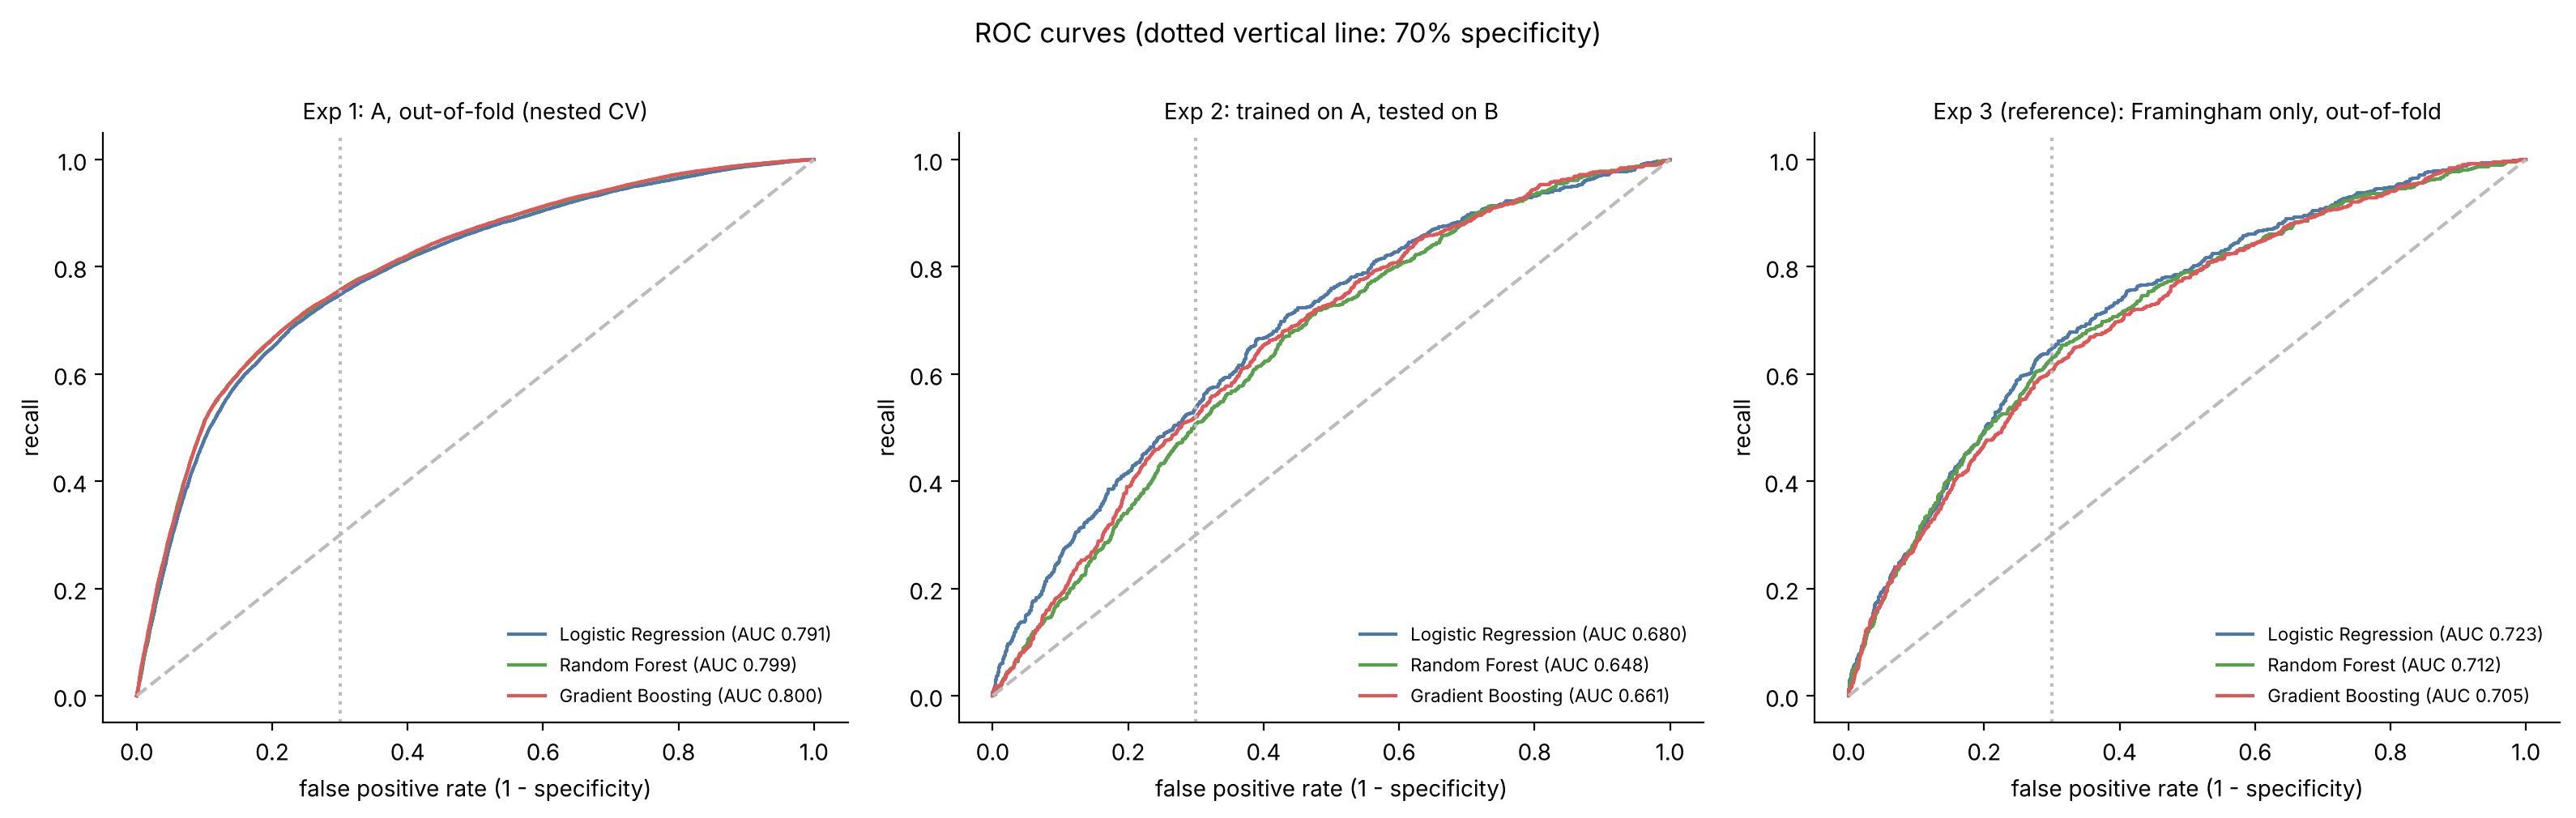

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for name in MODEL_SPECS:
    fpr, tpr, _ = roc_curve(yA, oof[name]); axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(yA, oof[name]):.3f})")
    fpr, tpr, _ = roc_curve(yB, pred_B[name]); axes[1].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(yB, pred_B[name]):.3f})")
    fpr, tpr, _ = roc_curve(yB, oof_b[name]); axes[2].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(yB, oof_b[name]):.3f})")
titles = ["Exp 1: A, out-of-fold (nested CV)", "Exp 2: trained on A, tested on B", "Exp 3 (reference): Framingham only, out-of-fold"]
for ax, t in zip(axes, titles):
    ax.plot([0, 1], [0, 1], color="#BBBBBB", linestyle="--"); ax.axvline(1 - SPEC_TARGET, color="#BBBBBB", linestyle=":")
    ax.set_xlabel("false positive rate (1 - specificity)"); ax.set_ylabel("recall"); ax.set_title(t, fontsize=10); ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle("ROC curves (dotted vertical line: 70% specificity)", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "roc_curves.png", dpi=130, bbox_inches="tight")
plt.show()

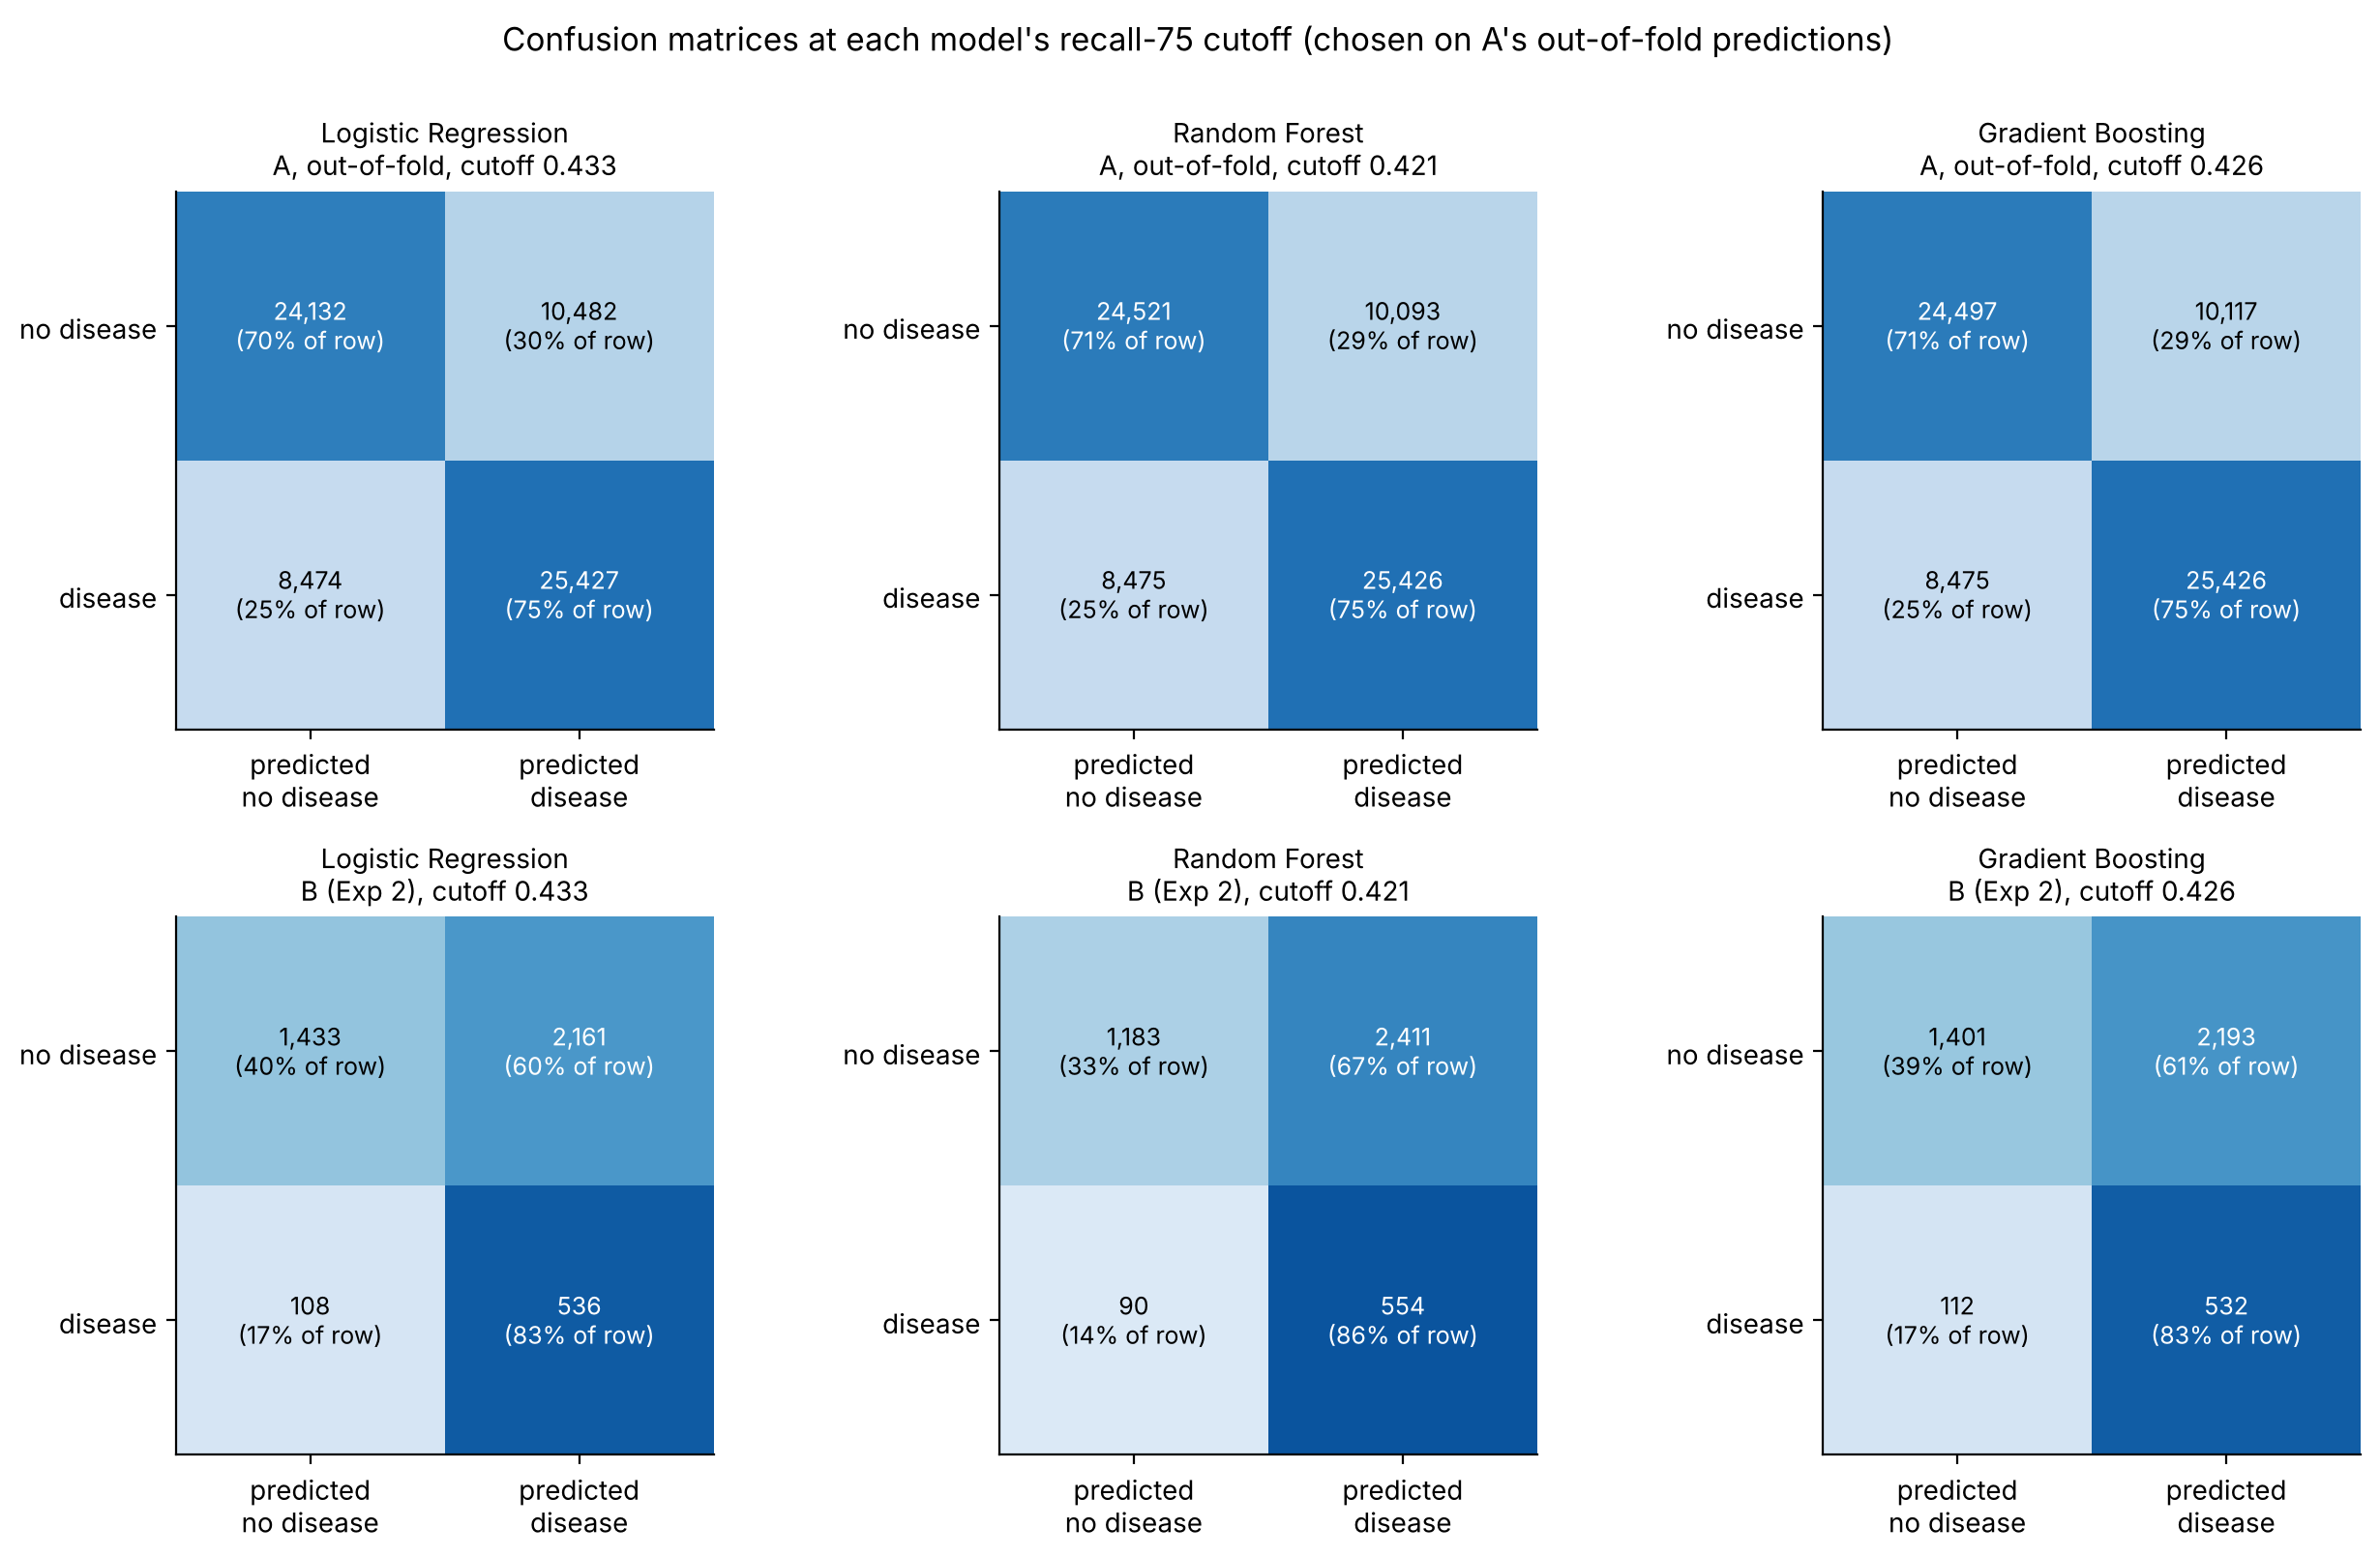

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for j, name in enumerate(MODEL_SPECS):
    c = cutoffs[name]["recall75"]
    for i, (lab, y, p) in enumerate([("A, out-of-fold", yA, oof[name]), ("B (Exp 2)", yB, pred_B[name])]):
        cm = confusion_matrix(y, (p >= c).astype(int))
        pct = cm / cm.sum(axis=1, keepdims=True) * 100
        ax = axes[i, j]
        ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
        for r in range(2):
            for k in range(2):
                ax.text(k, r, f"{cm[r, k]:,}\n({pct[r, k]:.0f}% of row)", ha="center", va="center", fontsize=9, color="white" if pct[r, k] > 55 else "black")
        ax.set_xticks([0, 1]); ax.set_xticklabels(["predicted\nno disease", "predicted\ndisease"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["no disease", "disease"])
        ax.set_title(f"{name}\n{lab}, cutoff {c:.3f}", fontsize=10)
fig.suptitle("Confusion matrices at each model's recall-75 cutoff (chosen on A's out-of-fold predictions)", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "confusion_matrices.png", dpi=130, bbox_inches="tight")
plt.show()

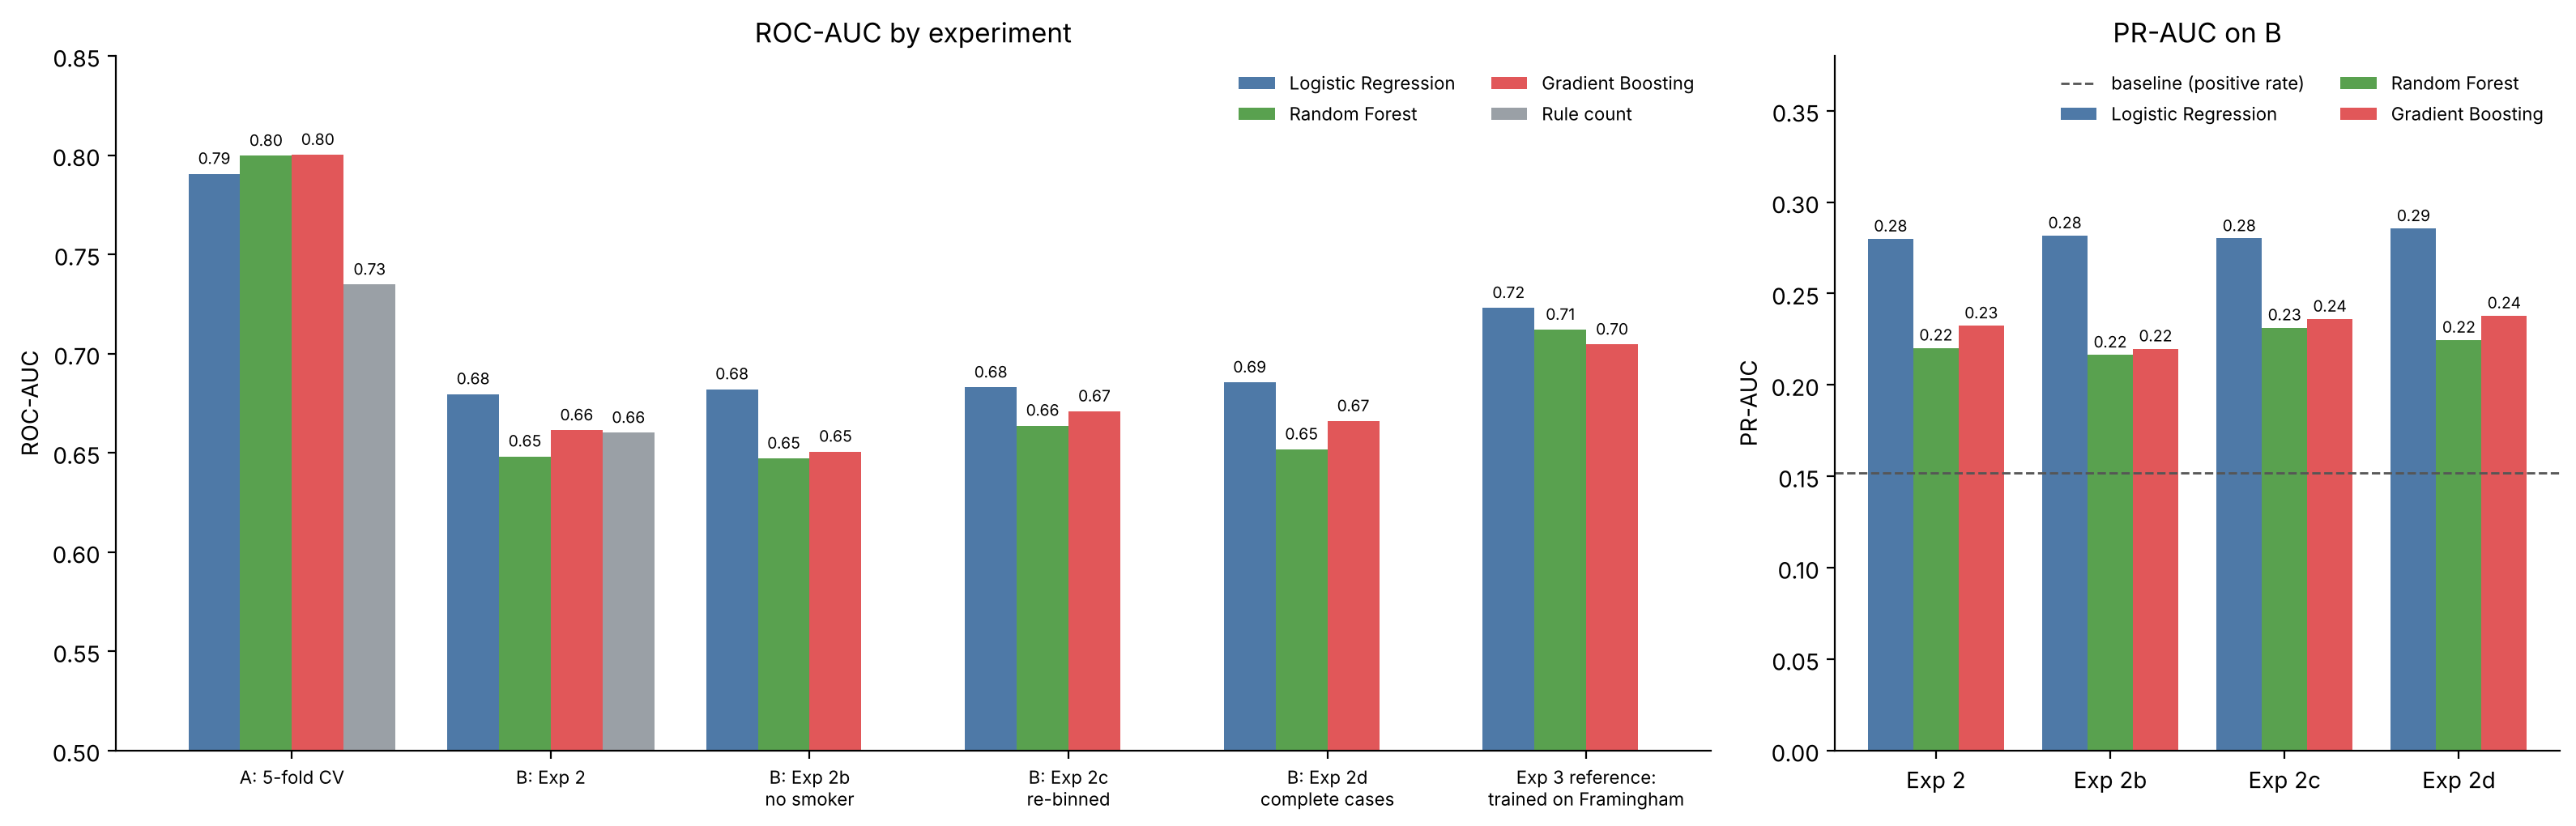

In [14]:
groups = [("A: 5-fold CV", "A_cv_roc_auc"), ("B: Exp 2", "B_roc_auc"), ("B: Exp 2b\nno smoker", "B_roc_auc_no_smoker"),
          ("B: Exp 2c\nre-binned", "B_roc_auc_rebinned"), ("B: Exp 2d\ncomplete cases", "B_roc_auc_complete_cases"),
          ("Exp 3 reference:\ntrained on Framingham", "B_ref_roc_auc_trained_on_framingham")]
bar_models = list(MODEL_SPECS) + ["Rule count (7 rules, no training)"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
w = 0.2; x = np.arange(len(groups))
for i, m in enumerate(bar_models):
    vals = [comparison.loc[comparison.model == m, col].iloc[0] if col in comparison else np.nan for _, col in groups]
    vals = [np.nan if pd.isna(v) else v for v in vals]
    key = "Rule count" if m.startswith("Rule") else m
    ax.bar(x + (i - 1.5) * w, vals, w, color=COLORS[key], label=key)
    for xi, v in zip(x + (i - 1.5) * w, vals):
        if not pd.isna(v):
            ax.text(xi, v + 0.005, f"{v:.2f}", ha="center", fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([g[0] for g in groups], fontsize=8); ax.set_ylim(0.5, 0.85); ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC by experiment"); ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax = axes[1]
pr_groups = [("Exp 2", "Exp 2:"), ("Exp 2b", "Exp 2b"), ("Exp 2c", "Exp 2c"), ("Exp 2d", "Exp 2d")]
x = np.arange(len(pr_groups)); w = 0.26
for i, m in enumerate(MODEL_SPECS):
    vals = [cross_df[(cross_df.model == m) & (cross_df.experiment.str.startswith(k))].pr_auc.iloc[0] for _, k in pr_groups]
    ax.bar(x + (i - 1) * w, vals, w, color=COLORS[m], label=m)
    for xi, v in zip(x + (i - 1) * w, vals):
        ax.text(xi, v + 0.004, f"{v:.2f}", ha="center", fontsize=7)
ax.axhline(yB.mean(), color="#555555", linestyle="--", linewidth=1, label="baseline (positive rate)")
ax.set_ylim(0, 0.38); ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.set_xticks(x); ax.set_xticklabels([g[0] for g in pr_groups]); ax.set_ylabel("PR-AUC"); ax.set_title("PR-AUC on B")
fig.tight_layout()
fig.savefig(FIG / "model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

## 10. Permutation importance on held-out folds

For each model and each outer fold of Exp 1, one attribute at a time is shuffled in the untouched fold and the drop in
ROC-AUC is recorded (5 shuffles per attribute). Bars show the mean over the five folds; whiskers show the spread between folds.

importance Logistic Regression done (3s)


importance Logistic Regression done (3s)


importance Random Forest done (23s)


importance Random Forest done (23s)


importance Gradient Boosting done (31s)


importance Gradient Boosting done (31s)


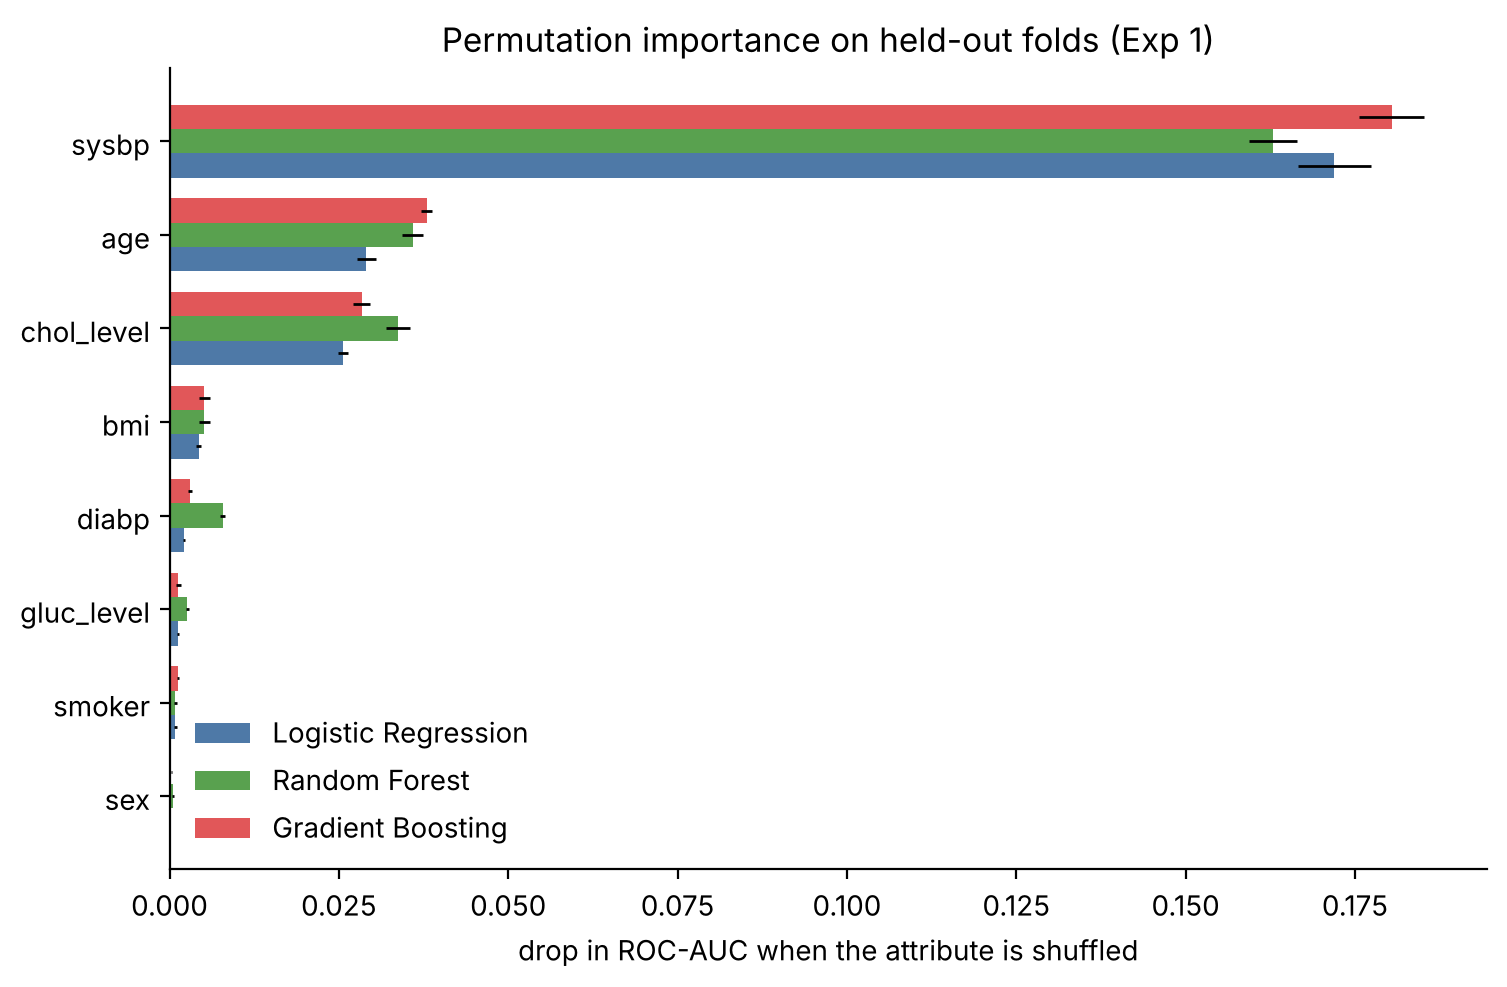

model,Gradient Boosting,Logistic Regression,Random Forest
feature,,,
sysbp,0.1804,0.1719,0.1629
age,0.0380,0.0291,0.0359
chol_level,0.0284,0.0256,0.0337
bmi,0.0051,0.0043,0.0051
diabp,0.0031,0.0021,0.0078
gluc_level,0.0013,0.0013,0.0027
smoker,0.0013,0.0009,0.0009
sex,0.0003,0.0000,0.0006


In [15]:
t0 = time.time()
imp_rows = []
for name in MODEL_SPECS:
    per_fold = []
    for est, te in fold_models[name]:
        r = permutation_importance(est, XA.iloc[te], yA[te], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
        per_fold.append(r.importances_mean)
    per_fold = np.array(per_fold)
    for k, feat in enumerate(FEATURES):
        imp_rows.append({"model": name, "feature": feat, "importance_mean": per_fold[:, k].mean(), "importance_sd": per_fold[:, k].std(ddof=1)})
    log(f"importance {name} done ({time.time()-t0:.0f}s)")
importance = pd.DataFrame(imp_rows)
importance.round(5).to_csv(RES / "feature_importance.csv", index=False)

order = importance[importance.model == BEST].sort_values("importance_mean")["feature"].tolist()
fig, ax = plt.subplots(figsize=(8.5, 5.2))
h = 0.26; y = np.arange(len(order))
for i, name in enumerate(MODEL_SPECS):
    d = importance[importance.model == name].set_index("feature").loc[order]
    ax.barh(y + (i - 1) * h, d.importance_mean, h, xerr=d.importance_sd, color=COLORS[name], label=name, error_kw={"elinewidth": 1})
ax.set_yticks(y); ax.set_yticklabels(order); ax.set_xlabel("drop in ROC-AUC when the attribute is shuffled")
ax.set_title("Permutation importance on held-out folds (Exp 1)"); ax.legend(frameon=False)
fig.savefig(FIG / "feature_importance.png", dpi=130, bbox_inches="tight")
plt.show()
importance.pivot(index="feature", columns="model", values="importance_mean").loc[order[::-1]].round(4)

## 11. Rule validation on A and B

Seven simple rules (`src/rules.py`). A rule never fires on a missing value. For each rule: how often it fires, the disease rate
when it fires and when it does not, and how much of the disease it catches. Then: how the disease rate grows with the number of rules fired.

In [16]:
rows, counts = [], []
for ds, df in [("A", a), ("B", b)]:
    m = rl.rules_fired_matrix(df); y = df[pp.TARGET].values; overall = y.mean()
    for r in rl.RULES:
        f = m[r.key].values
        rows.append({"dataset": ds, "rule": r.key, "description": r.label, "n_fired": int(f.sum()), "fired_pct": f.mean() * 100,
                     "disease_rate_when_fired_pct": y[f].mean() * 100 if f.any() else np.nan,
                     "disease_rate_when_not_fired_pct": y[~f].mean() * 100,
                     "recall_pct": y[f].sum() / y.sum() * 100, "specificity_pct": (~f[y == 0]).mean() * 100,
                     "lift": (y[f].mean() / overall) if f.any() else np.nan})
    n_fired = m.sum(axis=1).values
    for k in range(len(rl.RULES) + 1):
        sel_k = n_fired == k
        counts.append({"dataset": ds, "rules_fired": k, "n": int(sel_k.sum()), "disease_rate_pct": y[sel_k].mean() * 100 if sel_k.any() else np.nan})
rule_perf = pd.DataFrame(rows); rule_counts = pd.DataFrame(counts)
rule_perf.round(2).to_csv(RES / "rule_performance.csv", index=False)
rule_counts.round(2).to_csv(RES / "rule_count_vs_disease.csv", index=False)
print("Per rule")
display(rule_perf.drop(columns="description").round(1))
print("Number of rules fired vs disease rate")
display(rule_counts.pivot(index="rules_fired", columns="dataset", values=["n", "disease_rate_pct"]).round(1))
print(f"ROC-AUC of 'number of rules fired' used as a score: A {rc_A['roc_auc']:.3f}, B {rc_B['roc_auc']:.3f}")

Per rule


,dataset,rule,n_fired,fired_pct,disease_rate_when_fired_pct,disease_rate_when_not_fired_pct,recall_pct,specificity_pct,lift
0,A,high_sysbp,18441,26.9,83.7,36.9,45.5,91.3,1.7
1,A,high_diabp,19276,28.1,77.2,38.6,43.9,87.3,1.6
2,A,high_chol,17144,25.0,67.3,43.5,34.0,83.8,1.4
3,A,high_gluc,10265,15.0,60.3,47.6,18.3,88.2,1.2
4,A,obese,17874,26.1,62.5,44.9,33.0,80.7,1.3
5,A,smoker,6033,8.8,46.9,49.7,8.3,90.7,0.9
6,A,older,12484,18.2,66.7,45.6,24.6,88.0,1.3
7,B,high_sysbp,1283,30.3,24.7,11.1,49.2,73.1,1.6
8,B,high_diabp,1060,25.0,24.1,12.2,39.6,77.6,1.6
9,B,high_chol,3359,79.3,16.3,10.9,85.1,21.8,1.1


Number of rules fired vs disease rate


n         disease_rate_pct       
dataset            A       B                A      B
rules_fired                                         
0            22644.0   234.0             26.0    4.3
1            16674.0  1052.0             41.3    8.3
2            12898.0  1476.0             63.7   12.6
3             9035.0   763.0             76.9   20.3
4             4832.0   504.0             81.5   26.4
5             1994.0   178.0             82.5   34.8
6              422.0    30.0             82.7   33.3
7               16.0     1.0             93.8  100.0

ROC-AUC of 'number of rules fired' used as a score: A 0.735, B 0.660


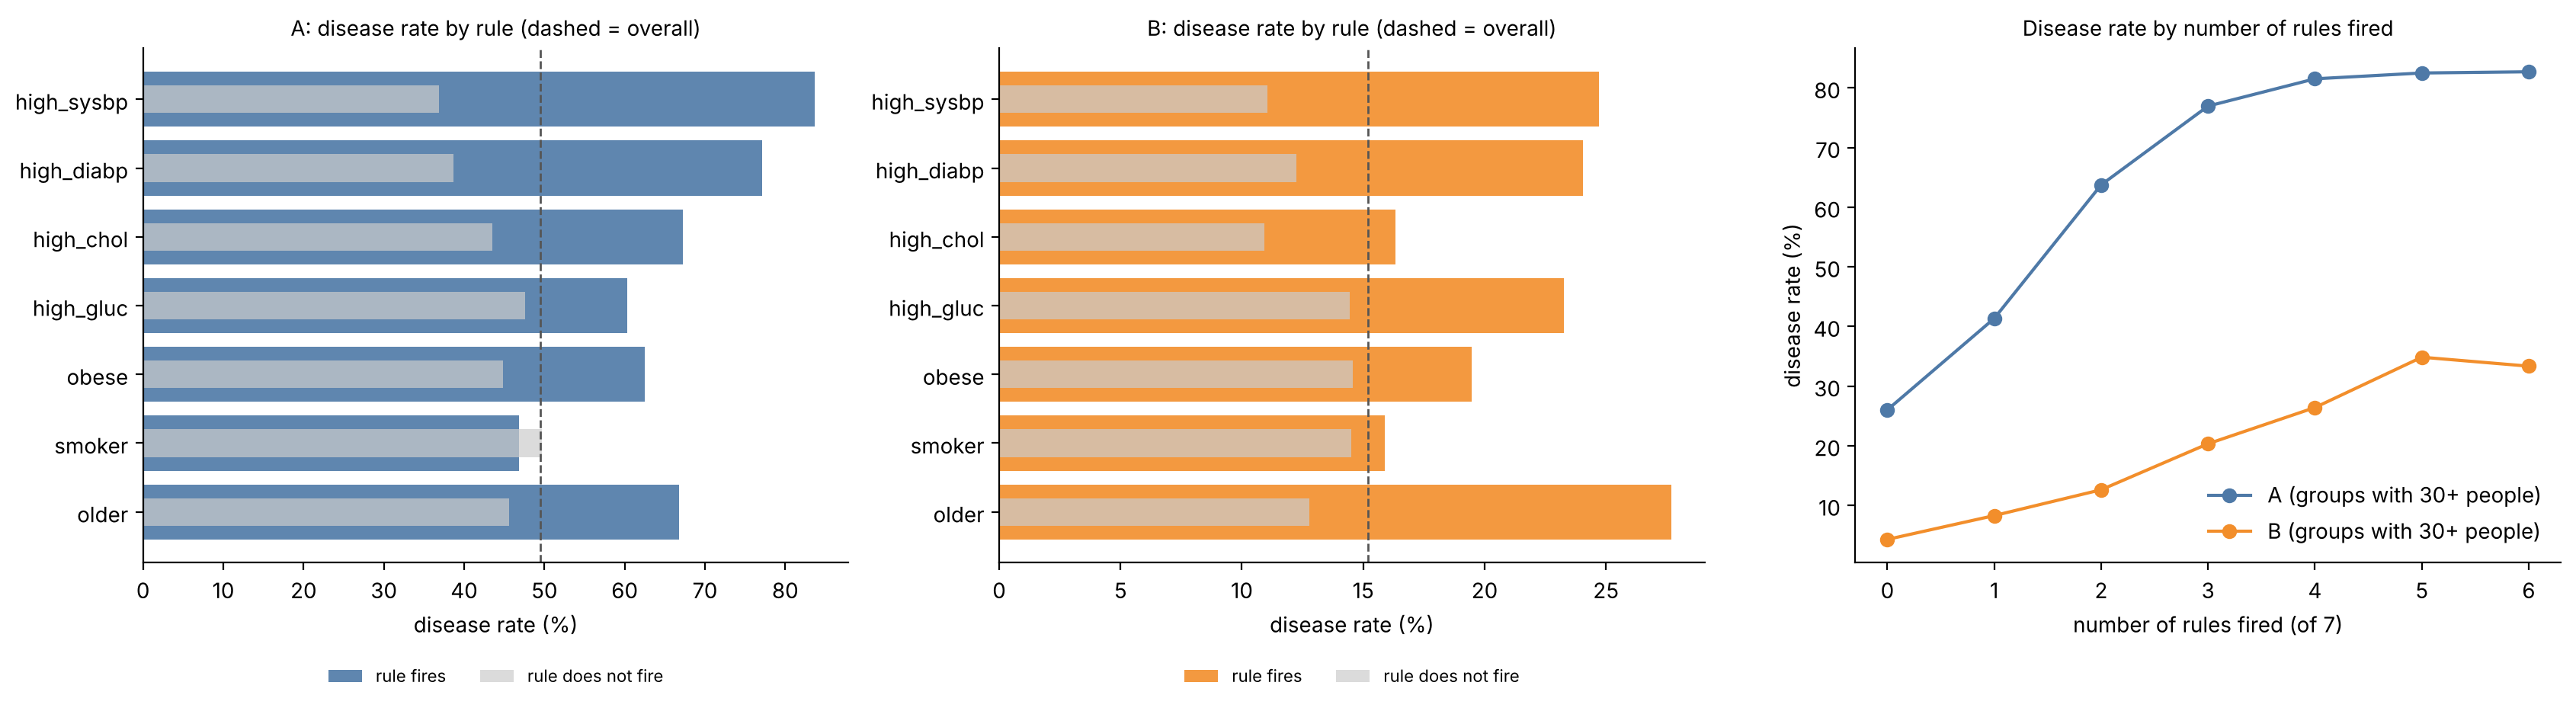

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, ds, col in [(axes[0], "A", "#4E79A7"), (axes[1], "B", "#F28E2B")]:
    d = rule_perf[rule_perf.dataset == ds]
    ax.barh(d.rule, d.disease_rate_when_fired_pct, color=col, alpha=0.9, label="rule fires")
    ax.barh(d.rule, d.disease_rate_when_not_fired_pct, color="#CCCCCC", alpha=0.7, height=0.4, label="rule does not fire")
    ax.axvline((a if ds == "A" else b).target.mean() * 100, color="#555555", linestyle="--", linewidth=1)
    ax.invert_yaxis(); ax.set_xlabel("disease rate (%)"); ax.set_title(f"{ds}: disease rate by rule (dashed = overall)", fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
ax = axes[2]
for ds, col in [("A", "#4E79A7"), ("B", "#F28E2B")]:
    d = rule_counts[(rule_counts.dataset == ds) & (rule_counts.n >= 30)]
    ax.plot(d.rules_fired, d.disease_rate_pct, marker="o", color=col, label=f"{ds} (groups with 30+ people)")
ax.set_xlabel("number of rules fired (of 7)"); ax.set_ylabel("disease rate (%)"); ax.set_title("Disease rate by number of rules fired", fontsize=10); ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "rule_validation.png", dpi=130, bbox_inches="tight")
plt.show()

## 12. Save the models and `model_info.json`

All three models are trained on all of A. `best_model.joblib` is a copy of the selected one. The app reads
`model_info.json` for the feature list, the cutoffs and the selection record.

In [18]:
files = {"Logistic Regression": "logistic_regression.joblib", "Random Forest": "random_forest.joblib", "Gradient Boosting": "gradient_boosting.joblib"}
for name, fn in files.items():
    joblib.dump(final[name], MODELS / fn)
joblib.dump(final[BEST], MODELS / "best_model.joblib")

info = {
    "best_model": BEST,
    "models": files,
    "features": FEATURES,
    "trained_on": f"Dataset A, Cardiovascular Disease dataset ({len(a):,} rows after cleaning)",
    "target_meaning": "cardio = cardiovascular disease present at the exam (A); the score is NOT a 10-year risk",
    "app_cutoff_rule": f"score cutoff giving {int(RECALL_TARGET*100)}% recall on A's out-of-fold predictions (nested CV)",
    "cutoffs": cutoffs,
    "cutoff_note": "Cutoffs come from a dataset that is about 50% positive; in lower-risk groups most flagged people will be false alarms.",
    "level_bands_mgdl": {"chol_level_2_from": pp.CHOL_CUTOFFS[0], "chol_level_3_from": pp.CHOL_CUTOFFS[1],
                         "gluc_level_2_from": pp.GLUC_CUTOFFS[0], "gluc_level_3_from": pp.GLUC_CUTOFFS[1]},
    "selection_rule": f"highest mean recall at {int(SPEC_TARGET*100)}% specificity in nested 5-fold CV on A; models within 0.02 are tied and ranked by mean ROC-AUC",
    "selection_table": json.loads(sel.round(5).reset_index().to_json(orient="records")),
    "best_params": best_params,
    "a_positive_rate": float(yA.mean()),
    "b_positive_rate": float(yB.mean()),
    "sklearn_version": sklearn.__version__,
    "seed": SEED,
}
(RES / "model_info.json").write_text(json.dumps(info, indent=2))
print("saved:", sorted(p.name for p in MODELS.glob("*.joblib")))
print("selected model:", BEST)

saved: ['best_model.joblib', 'gradient_boosting.joblib', 'logistic_regression.joblib', 'random_forest.joblib', 'soft_voting_ensemble.joblib']
selected model: Gradient Boosting


## 13. Summary of results
Every number below is read from the result tables above.

In [19]:
b2 = cross_df[cross_df.experiment.str.startswith("Exp 2:")].set_index("model")
print(f"Selected on A only: {BEST}")
print(f"\nWithin A (nested 5-fold CV), mean ROC-AUC:        " + ", ".join(f"{n} {folds[folds.model==n].roc_auc.mean():.3f}" for n in MODEL_SPECS))
print(f"On B (train A, test B), ROC-AUC [95% bootstrap CI]: " + ", ".join(f"{n} {b2.loc[n,'roc_auc']:.3f} [{b2.loc[n,'roc_auc_ci_low']:.3f}-{b2.loc[n,'roc_auc_ci_high']:.3f}]" for n in MODEL_SPECS))
print(f"On B, PR-AUC (baseline {yB.mean():.3f}):             " + ", ".join(f"{n} {b2.loc[n,'pr_auc']:.3f}" for n in MODEL_SPECS))
print(f"Framingham-trained reference ROC-AUC (Exp 3):      " + ", ".join(f"{n} {exp3[(exp3.model==n)&(exp3.fold=='pooled')].roc_auc.iloc[0]:.3f}" for n in MODEL_SPECS))
print(f"Rule count as a score, ROC-AUC:                    A {rc_A['roc_auc']:.3f}, B {rc_B['roc_auc']:.3f}")
for e in ("Exp 2b", "Exp 2c", "Exp 2d"):
    d = cross_df[cross_df.experiment.str.startswith(e)].set_index("model")
    print(f"{cross_df[cross_df.experiment.str.startswith(e)].experiment.iloc[0]:42s} ROC-AUC: " + ", ".join(f"{n} {d.loc[n,'roc_auc']:.3f}" for n in MODEL_SPECS))
print(f"\nAt A's recall-75 cutoff, share of B flagged (Exp 2): " + ", ".join(f"{n} {b2.loc[n,'flagged_pct']:.0f}%" for n in MODEL_SPECS))

Selected on A only: Gradient Boosting

Within A (nested 5-fold CV), mean ROC-AUC:        Logistic Regression 0.791, Random Forest 0.800, Gradient Boosting 0.800
On B (train A, test B), ROC-AUC [95% bootstrap CI]: Logistic Regression 0.680 [0.659-0.701], Random Forest 0.648 [0.628-0.669], Gradient Boosting 0.661 [0.640-0.682]
On B, PR-AUC (baseline 0.152):             Logistic Regression 0.280, Random Forest 0.220, Gradient Boosting 0.232
Framingham-trained reference ROC-AUC (Exp 3):      Logistic Regression 0.723, Random Forest 0.712, Gradient Boosting 0.705
Rule count as a score, ROC-AUC:                    A 0.735, B 0.660
Exp 2b: without smoker                     ROC-AUC: Logistic Regression 0.682, Random Forest 0.647, Gradient Boosting 0.651
Exp 2c: B levels re-binned to A's shares   ROC-AUC: Logistic Regression 0.683, Random Forest 0.664, Gradient Boosting 0.671
Exp 2d: B complete cases only              ROC-AUC: Logistic Regression 0.685, Random Forest 0.652, Gradient Boosting 0

## 14. Findings and limits

* **Within A** all three models are close: ROC-AUC about 0.79 to 0.80. They are tied on the selection score (recall at 70% specificity,
  within 0.02), so the choice falls to ROC-AUC, which picks Gradient Boosting by a very small margin over Random Forest.
* **On B** ROC-AUC drops to about 0.65 to 0.68 (95% bootstrap intervals roughly 0.03 to 0.04 wide), and PR-AUC is 0.22 to 0.28 against a baseline of 0.15.
  The models do rank people better than chance, but clearly less well than within A. The model that was best on A is not the one that transfers best:
  Logistic Regression is highest on B and Random Forest lowest. The intervals overlap, so the ordering is suggestive, not established. B was not used to choose a model.
* **A reference ceiling:** models trained on Framingham itself with the same 8 attributes reach ROC-AUC about 0.70 to 0.72 (Exp 3). So part of the gap
  is the limit of these 8 attributes for a 10-year outcome, and the remaining 0.04 to 0.06 is what moving from A's label and population to B costs.
* **Rules:** simply counting how many of the 7 rules fire gives ROC-AUC about 0.66 on B, in the same range as the trained models.
* **Exp 2b (no smoker):** changes ROC-AUC by 0.01 or less, so smoking is not what drives the drop.
* **Exp 2c (levels re-binned):** helps Random Forest (+0.016) and Gradient Boosting (+0.010) more than Logistic Regression (+0.003), so the different meaning of the cholesterol levels matters for the tree models.
* **Exp 2d (complete cases):** changes ROC-AUC by 0.005 or less, so B's missing values are not a major factor.
* **Cutoffs do not transfer.** At A's recall-75 cutoff, 64% to 70% of B is flagged, with specificity of 33% to 40%. A is about 50% positive and B about 15%, so a cutoff learned on A flags far too many people on B.
* **Not tested:** whether Cardio's heavily rounded blood-pressure readings (97% multiples of 10, against 12% in Framingham) explain why the tree models transfer worse. It is consistent with the results but is a hypothesis.
  Ages in B go slightly above A's range (4% of B is older than 64).
* **What the score means:** it estimates "disease present at the exam" as defined in the Cardio data, not 10-year risk, and it is not calibrated for lower-risk groups.